<a href="https://colab.research.google.com/github/farrelrassya/teachingMLDL/blob/main/01.%20decision_tree_knn_basic_to_advanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Tree & K-Nearest Neighbors
## Dari dasar sampai lanjutan, dengan Python dan hitungan manual

**Tujuan:** setelah belajar, kamu bisa menjelaskan keputusan model, menghitung satu split atau satu prediksi KNN dengan tangan, dan mengevaluasi model tanpa kebocoran data.

Materi disusun dalam bahasa Indonesia dari **trees.pdf** (25 halaman), **Telyu-03.pptx** (36 slide), dan **Week3 (1).pdf** (12 halaman berupa gambar). Penjelasan, contoh kecil, kode, dan latihan ditulis oleh Codex. Claude CLI membantu penataan dan navigasi; isi matematis tetap dipertahankan.

**Pasangan notebook:** `hitungan_manual_decision_tree_knn.md`. Cari ID seperti **C04** dalam kedua file untuk menghubungkan hitungan dengan kode. Angka di contoh kecil dibuat agar bisa diperiksa dengan kalkulator. Dataset simulasi yang lebih besar dianalisis lewat beberapa sampel dan rumus pembangkit, bukan dihitung satu per satu dengan tangan.

**Cara belajar:** baca intuisi → baca persamaan → jalankan kode → bandingkan dengan hitungan manual → ubah satu parameter. Jangan langsung lompat ke tuning sebelum memahami split dan jarak.

**Rute:** Dasar (0–5) → Menengah (6–12) → Lanjutan (13–20) → latihan (21) dan rujukan (22–23). Kamu cukup mengenal variabel, list, fungsi, dan `if` Python; bagian 1 mengulang NumPy yang diperlukan.

**Menjalankan:** buka di Jupyter, VS Code, atau Google Colab; gunakan **Restart Kernel → Run All**. Setelah pustaka terpasang, semua dataset tersedia lokal atau dibuat oleh kode, sehingga tidak ada unduhan dataset. Output contoh dan grafik sudah disimpan agar bisa dibaca tanpa menjalankan ulang.

Jika import gagal, aktifkan lalu jalankan baris `%pip` di C00 satu kali, kemudian restart kernel. Python 3.10+ dianjurkan. Instalasi pustaka pertama membutuhkan internet.

<a id="daftar-isi"></a>
## Daftar Isi

**Dasar (Bab 0–5)**
- [0. Persiapan dan kamus simbol](#bab-0)
- [1. Dari data menuju prediksi](#bab-1)
- [2. Pohon adalah rangkaian pertanyaan](#bab-2)
- [3. Mengukur campuran kelas: Gini, entropy, dan error](#bab-3)
- [4. Memilih split: jangan lupa bobot ukuran anak](#bab-4)
- [5. Membuat CART kecil dari nol](#bab-5)

**Menengah (Bab 6–12)**
- [6. Mengapa tree terlalu dalam bisa menghafal?](#bab-6)
- [7. KNN: jarak → urutan tetangga → voting](#bab-7)
- [8. Atribut kategori: Hamming dan contoh tip restoran](#bab-8)
- [9. Scaling dapat mengubah siapa yang terdekat](#bab-9)
- [10. Melihat decision boundary dan pengaruh k](#bab-10)
- [11. Eksperimen yang adil: train, validation/CV, test](#bab-11)
- [12. Membaca metrik, lalu membuka test set](#bab-12)

**Lanjutan (Bab 13–20)**
- [13. Twoing, prior kelas, dan biaya kesalahan](#bab-13)
- [14. Missing values, kategori, dan surrogate split](#bab-14)
- [15. Curse of dimensionality dan PCA](#bab-15)
- [16. Kasus sumber: digit tujuh segmen yang rusak](#bab-16)
- [17. Kasus sumber: waveform dengan 21 fitur](#bab-17)
- [18. Oblique split: satu garis miring atau banyak tangga?](#bab-18)
- [19. Perluasan: tree dan KNN untuk regresi](#bab-19)
- [20. Membandingkan mekanisme dan biaya komputasi](#bab-20)

**Latihan dan Referensi (Bab 21–23)**
- [21. Delapan pertanyaan untuk memeriksa intuisi](#bab-21)
- [22. Ringkasan persamaan dan panduan memilih langkah berikut](#bab-22)
- [23. Peta sumber dan rujukan implementasi](#bab-23)

---
### Tingkat Dasar — Bab 0–5

Tujuan belajar: menyiapkan simbol, mengikuti alur dari data menuju prediksi, melihat pohon sebagai rangkaian pertanyaan, mengukur campuran kelas, memilih split, dan membangun CART kecil dari nol.

[Kembali ke Daftar Isi](#daftar-isi)

<a id="bab-0"></a>

## 0. Persiapan dan kamus simbol

| Simbol | Makna | Contoh |
|---|---|---|
| $N$ | banyak sampel | 6 baris |
| $p$ atau $d$ | banyak fitur | umur dan pendapatan: 2 |
| $X\in\mathbb R^{N\times p}$ | matriks fitur | satu baris = satu objek |
| $y_i$ | label sampel ke-$i$ | 0 atau 1 |
| $K$ | jumlah kelas | klasifikasi tiga kelas: $K=3$ |
| $k$ | jumlah tetangga KNN | gunakan 5 tetangga |
| $t,t_L,t_R$ | node, anak kiri, anak kanan | wilayah sebelum/sesudah split |
| $p_j(t)$ | proporsi kelas $j$ di node $t$ | 3 dari 4 = 0.75 |

Huruf **K** untuk kelas berbeda dari **k** untuk tetangga. Dalam notebook, label biasanya dimulai dari 0. Ini hanya penomoran, bukan urutan kualitas kelas.

[Daftar isi](#daftar-isi)

In [1]:
# C00
# Jika perlu, hapus tanda # pada baris berikut, jalankan, lalu restart kernel:
# %pip install numpy pandas matplotlib scikit-learn

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, make_moons
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 6)
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)

Python: 3.13.16 | scikit-learn: 1.6.1


<a id="bab-1"></a>

## 1. Dari data menuju prediksi

Bayangkan dua cara memberi saran. **Decision Tree** menulis aturan terlebih dahulu: jika syarat A terpenuhi, periksa B. **KNN** menyimpan contoh lalu bertanya: siapa yang paling mirip dengan objek baru?

Keduanya termasuk *supervised learning*: saat belajar kita punya fitur $X$ dan label $y$. Saat memprediksi objek baru, labelnya belum diketahui.

$$\mathcal D=\{(\mathbf x_i,y_i)\}_{i=1}^{N},\qquad \hat y=g(\mathbf x).$$

Tree disebut **eager learner** karena membangun aturan saat `fit`. KNN disebut **lazy learner** karena keputusan utamanya dibuat saat `predict`. `fit` KNN tetap punya pekerjaan, misalnya menyimpan data dan dapat membangun indeks pencarian.

**Sumber:** Week3 halaman 3–4, 7, 10; Telyu slide 4–8 dan 26–31.

[Daftar isi](#daftar-isi)

In [2]:
# C01
# X punya 6 baris dan 1 fitur. y punya satu label untuk setiap baris.
X_toy = np.arange(1, 7, dtype=float).reshape(-1, 1)
y_toy = np.array([0, 0, 1, 1, 1, 0])
print("shape X:", X_toy.shape, "shape y:", y_toy.shape)
print("Fitur baris pertama:", X_toy[0], "label:", y_toy[0])
mask_kiri = X_toy[:, 0] <= 2.5
print("Mask kiri:", mask_kiri)
print("Label yang masuk kiri:", y_toy[mask_kiri])
display(pd.DataFrame({"x": X_toy[:, 0], "y": y_toy}))

shape X: (6, 1) shape y: (6,)
Fitur baris pertama: [1.] label: 0
Mask kiri: [ True  True False False False False]
Label yang masuk kiri: [0 0]


,x,y
0,1.0,0
1,2.0,0
2,3.0,1
3,4.0,1
4,5.0,1
5,6.0,0


<a id="bab-2"></a>

## 2. Pohon adalah rangkaian pertanyaan

**Root** adalah pertanyaan awal, **internal node** adalah pertanyaan lanjutan, dan **leaf** adalah tempat keputusan akhir. Setiap objek menempuh tepat satu jalur.

Contoh pengajaran: pinjaman disetujui jika riwayat kredit baik **dan** rasio pinjaman terhadap agunan kecil **dan** pendapatan cukup. Ini hanya aturan sintetis untuk belajar, bukan model keputusan kredit sungguhan.

$$\text{setuju}=A\land B\land C.$$

Jika dua jalur menghasilkan kelas yang sama, aturan kelas itu bisa berupa **OR antarjalur**, dengan **AND di dalam jalur**. Bentuk ini disebut *disjunctive normal form* (DNF), misalnya $(A\land B)\lor(\neg A\land C)$.

Ada $2^3=8$ kombinasi untuk tiga atribut biner. Pada **full binary tree**, setiap internal node punya tepat dua anak; jika jumlah leaf $L$, jumlah internal node $I=L-1$. Untuk pohon nonbiner rumus itu tidak selalu benar: secara umum $L=1+\sum_{v\text{ internal}}(\text{jumlah anak}(v)-1)$.

Di scikit-learn, cabang kiri berarti **fitur ≤ threshold**. Arah true/false bukan hukum universal; baca label cabang.

**Sumber:** Telyu slide 5–10; trees halaman 2–5; Week3 halaman 5–6.

[Daftar isi](#daftar-isi)

,kredit_baik,rasio_kecil,pendapatan_cukup,setuju
0,0,0,0,0
1,0,0,1,0
2,0,1,0,0
3,0,1,1,0
4,1,0,0,0
5,1,0,1,0
6,1,1,0,0
7,1,1,1,1


|--- rasio_kecil <= 0.50
|   |--- class: 0
|--- rasio_kecil >  0.50
|   |--- pendapatan_cukup <= 0.50
|   |   |--- class: 0
|   |--- pendapatan_cukup >  0.50
|   |   |--- kredit_baik <= 0.50
|   |   |   |--- class: 0
|   |   |--- kredit_baik >  0.50
|   |   |   |--- class: 1

Leaf: 4 internal: 3 cek I=L-1: True


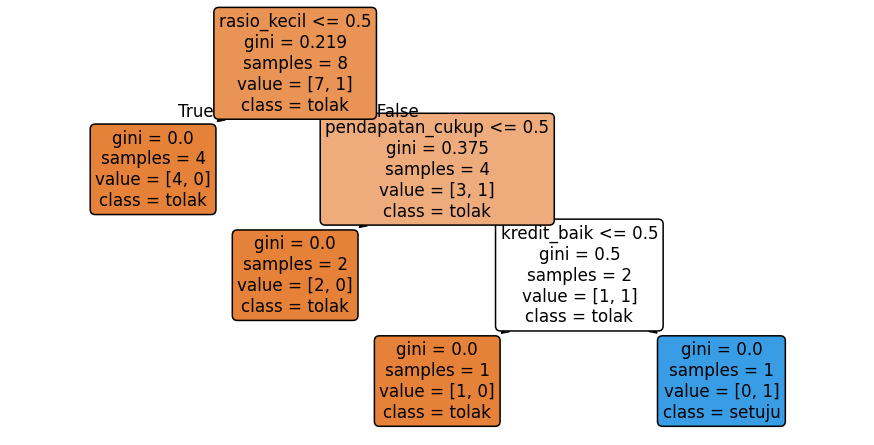

In [3]:
# C02
from itertools import product
loan = pd.DataFrame(list(product([0, 1], repeat=3)),
                    columns=["kredit_baik", "rasio_kecil", "pendapatan_cukup"])
loan["setuju"] = loan.all(axis=1).astype(int)
display(loan)
loan_tree = DecisionTreeClassifier(random_state=SEED).fit(loan.iloc[:, :3], loan["setuju"])
print(export_text(loan_tree, feature_names=list(loan.columns[:3])))
L = loan_tree.get_n_leaves()
I = loan_tree.tree_.node_count - L
print("Leaf:", L, "internal:", I, "cek I=L-1:", I == L - 1)
fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(loan_tree, feature_names=list(loan.columns[:3]),
          class_names=["tolak", "setuju"], filled=True, rounded=True, ax=ax)
plt.show()

<a id="bab-3"></a>

## 3. Mengukur campuran kelas: Gini, entropy, dan error

Sebuah kotak berisi 4 bola merah dan 0 biru sangat mudah ditebak. Kotak berisi 2 merah dan 2 biru lebih membingungkan. **Impurity** mengukur seberapa bercampur kelas di suatu node.

Untuk hitungan tanpa bobot, $p_j(t)=N_j(t)/N(t)$:

$$G(t)=1-\sum_{j=1}^{K}p_j(t)^2,$$
$$H(t)=-\sum_{j=1}^{K}p_j(t)\log_2p_j(t),\qquad 0\log_2 0:=0,$$
$$r(t)=1-\max_jp_j(t).$$

Gini bisa dibaca sebagai peluang dua pengambilan label independen dari distribusi node memberikan kelas berbeda. Entropy mengukur ketidakpastian dalam **bit** karena kita memakai log basis 2. Misclassification error adalah proporsi kesalahan jika semua anggota node diberi label mayoritas.

Untuk dua kelas seimbang: Gini $=0.5$, entropy $=1$, error $=0.5$. Untuk node murni: semuanya 0. Untuk $K$ kelas seimbang, maksimum Gini $=1-1/K$ dan entropy $=\log_2 K$. Jadi Gini tidak selalu dibatasi 0.5.

Error lebih datar terhadap perubahan proporsi, sehingga sering kurang sensitif sebagai kriteria split. Tidak ada aturan bahwa Gini selalu mengungguli entropy pada semua dataset.

**Sumber:** trees halaman 6–9 dan 13; Telyu slide 15; Week3 halaman 6, 9.

[Daftar isi](#daftar-isi)

,node,gini,entropy,error
0,murni 4:0,0.000000,-0.000000,0.000000
1,campuran 3:1,0.375000,0.811278,0.250000
2,seimbang 2:2,0.500000,1.000000,0.500000
3,3 kelas seimbang,0.666667,1.584963,0.666667


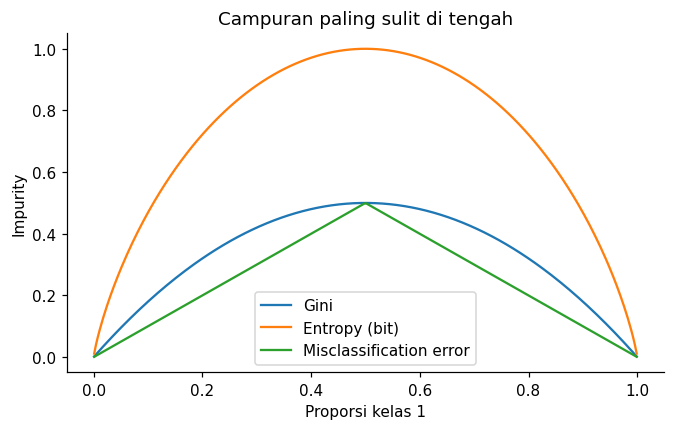

In [4]:
# C03
def class_probabilities(labels):
    _, counts = np.unique(labels, return_counts=True)
    if len(counts) == 0:
        raise ValueError("Node kosong tidak punya proporsi kelas.")
    return counts / counts.sum()

def impurity(labels, criterion="gini"):
    probs = class_probabilities(labels)
    if criterion == "gini":
        return float(1 - np.sum(probs ** 2))
    if criterion == "entropy":
        return float(-np.sum(probs * np.log2(probs)))  # probs di sini > 0
    if criterion == "error":
        return float(1 - probs.max())
    raise ValueError("criterion harus gini, entropy, atau error")

examples = {"murni 4:0": [0, 0, 0, 0], "campuran 3:1": [0, 0, 0, 1],
            "seimbang 2:2": [0, 0, 1, 1], "3 kelas seimbang": [0, 1, 2]}
display(pd.DataFrame([{ "node": name, **{c: impurity(y, c)
    for c in ["gini", "entropy", "error"]}} for name, y in examples.items()]))
assert np.isclose(impurity([0, 0, 0, 1]), 0.375)
assert np.isclose(impurity([0, 0, 0, 1], "entropy"), 0.8112781244591328)

q = np.linspace(0.001, 0.999, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(q, 2*q*(1-q), label="Gini")
ax.plot(q, -q*np.log2(q)-(1-q)*np.log2(1-q), label="Entropy (bit)")
ax.plot(q, np.minimum(q, 1-q), label="Misclassification error")
ax.set(xlabel="Proporsi kelas 1", ylabel="Impurity", title="Campuran paling sulit di tengah")
ax.legend(); plt.show()

<a id="bab-4"></a>

## 4. Memilih split: jangan lupa bobot ukuran anak

Tree mencoba pertanyaan $x_j\le c$. Kandidat threshold numerik cukup di antara dua nilai unik berurutan, karena pembagian data latih tidak berubah di dalam interval itu.

$$c_m=\frac{v_m+v_{m+1}}2,$$
$$\Delta i(s,t)=i(t)-\frac{N_L}{N_t}i(t_L)-\frac{N_R}{N_t}i(t_R).$$

**Intuisi:** satu anak berisi 99 sampel harus memengaruhi penilaian lebih besar daripada satu anak berisi 1 sampel. Rata-rata biasa tanpa bobot akan menyesatkan.

Gunakan data C01: $x=[1,2,3,4,5,6]$, $y=[0,0,1,1,1,0]$. Pada threshold 2.5, kiri berisi `[0,0]`, kanan `[1,1,1,0]`. Parent Gini 0.5; impurity sesudah split $=(2/6)(0)+(4/6)(0.375)=0.25$. Jadi gain $=0.25$.

Perhatikan beda bobot **lokal** dan **global** dalam trees.pdf:

$$p(t)=\frac{N_t}{N},\quad I(t)=p(t)i(t),\quad
 I(T)=\sum_{t\in\operatorname{leaves}(T)}I(t),\quad
\Delta I(s,t)=p(t)\Delta i(s,t).$$

Jika node hanya memuat 40% seluruh data, gain lokal 0.25 memberi pengurangan impurity seluruh pohon $0.4\times0.25=0.10$. Pada root, $p(t)=1$.

**Sumber:** trees halaman 5, 7–8.

[Daftar isi](#daftar-isi)

In [5]:
# C04
def split_table(X, y, criterion="gini"):
    rows = []
    parent = impurity(y, criterion)
    for feature in range(X.shape[1]):
        vals = np.unique(X[:, feature])
        for threshold in (vals[:-1] + vals[1:]) / 2:
            left = X[:, feature] <= threshold
            n_left, n_right = left.sum(), (~left).sum()
            left_i = impurity(y[left], criterion)
            right_i = impurity(y[~left], criterion)
            after = (n_left*left_i + n_right*right_i) / len(y)
            rows.append(dict(feature=feature, threshold=threshold,
                n_left=n_left, n_right=n_right, left_impurity=left_i,
                right_impurity=right_i, weighted_after=after, gain=parent-after))
    return pd.DataFrame(rows)

split_gini = split_table(X_toy, y_toy)
display(split_gini)
best_split = split_gini.loc[split_gini["gain"].idxmax()]
display(pd.DataFrame([{ "criterion": c, **split_table(X_toy, y_toy, c)
    .query("threshold == 2.5").iloc[0].to_dict()}
    for c in ["gini", "entropy", "error"]]))
assert best_split["threshold"] == 2.5
assert np.isclose(best_split["gain"], 0.25)
print("Gain global jika p(t)=0.4:", 0.4 * best_split["gain"])

,feature,threshold,n_left,n_right,left_impurity,right_impurity,weighted_after,gain
0,0,1.5,1,5,0.000000,0.480000,0.400000,0.100000
1,0,2.5,2,4,0.000000,0.375000,0.250000,0.250000
2,0,3.5,3,3,0.444444,0.444444,0.444444,0.055556
3,0,4.5,4,2,0.500000,0.500000,0.500000,0.000000
4,0,5.5,5,1,0.480000,0.000000,0.400000,0.100000


,criterion,feature,threshold,n_left,n_right,left_impurity,right_impurity,weighted_after,gain
0,gini,0.0,2.5,2.0,4.0,0.0,0.375000,0.250000,0.250000
1,entropy,0.0,2.5,2.0,4.0,-0.0,0.811278,0.540852,0.459148
2,error,0.0,2.5,2.0,4.0,0.0,0.250000,0.166667,0.333333


Gain global jika p(t)=0.4: 0.1


<a id="bab-5"></a>

## 5. Membuat CART kecil dari nol

**CART** membagi node menjadi dua anak. Pada setiap node, pilih split terbaik saat itu (**greedy**), lalu ulangi pada setiap anak. Greedy tidak menjamin pohon yang terbaik secara global.

Berhenti jika node murni, kedalaman sudah mencapai batas, tidak ada kandidat valid, atau gain terbaik terlalu kecil. Setelah berhenti, prediksi kelas mayoritas:

$$\kappa(t)=\arg\max_jp_j(t),\qquad \hat P(y=j\mid\mathbf x)=p_j(t(\mathbf x)).$$

Probabilitas leaf adalah estimasi dari sampel di leaf; leaf yang hanya berisi satu sampel tidak memberikan kepastian dunia nyata sebesar 100%.

Implementasi C05 sengaja dibatasi pada fitur numerik, tanpa missing value, tanpa sample weight, tanpa pruning, dan dataset kecil. Ini untuk memahami alur; untuk pekerjaan nyata gunakan pustaka yang teruji. Jika kelas seri, pilih label terkecil secara deterministik.

**Sumber:** trees halaman 4, 12–14; Telyu slide 11, 18, 23.

[Daftar isi](#daftar-isi)

In [6]:
# C05
def grow_cart(X, y, depth=0, max_depth=2, min_gain=1e-12):
    classes, counts = np.unique(y, return_counts=True)
    node = {"prediction": classes[np.argmax(counts)], "n": len(y),
            "gini": impurity(y), "depth": depth}
    if depth >= max_depth or node["gini"] <= 1e-12:
        return node
    candidates = split_table(X, y)
    if candidates.empty:
        return node
    best = candidates.loc[candidates["gain"].idxmax()]
    if best["gain"] <= min_gain:
        return node
    f, threshold = int(best["feature"]), float(best["threshold"])
    left = X[:, f] <= threshold
    node.update(feature=f, threshold=threshold,
        left=grow_cart(X[left], y[left], depth+1, max_depth, min_gain),
        right=grow_cart(X[~left], y[~left], depth+1, max_depth, min_gain))
    return node

def predict_cart_one(node, x):
    while "feature" in node:
        node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
    return node["prediction"]

def print_cart(node, indent=""):
    if "feature" not in node:
        print(f"{indent}leaf: kelas={node['prediction']}, n={node['n']}")
    else:
        print(f"{indent}x{node['feature']} <= {node['threshold']:.2f}")
        print_cart(node["left"], indent+"  L: ")
        print_cart(node["right"], indent+"  R: ")

manual_tree = grow_cart(X_toy, y_toy)
print_cart(manual_tree)
manual_pred = np.array([predict_cart_one(manual_tree, x) for x in X_toy])
assert np.array_equal(manual_pred, y_toy)
print("Prediksi latih:", manual_pred)
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_toy, y_toy)
assert np.isclose(stump.tree_.threshold[0], 2.5)
print("Threshold root scikit-learn:", stump.tree_.threshold[0])
print("Probabilitas stump untuk x=4:", stump.predict_proba([[4]])[0])

x0 <= 2.50
  L: leaf: kelas=0, n=2
  R: x0 <= 5.50
  R:   L: leaf: kelas=1, n=3
  R:   R: leaf: kelas=0, n=1
Prediksi latih: [0 0 1 1 1 0]
Threshold root scikit-learn: 2.5
Probabilitas stump untuk x=4: [0.25 0.75]


---
### Tingkat Menengah — Bab 6–12

Tujuan belajar: memahami mengapa tree yang terlalu dalam bisa menghafal, mengenal alur kerja KNN, menangani atribut kategori, melihat peran scaling, decision boundary, dan nilai k, lalu merancang eksperimen yang adil serta membaca metrik.

[Kembali ke Daftar Isi](#daftar-isi)

<a id="bab-6"></a>

## 6. Mengapa tree terlalu dalam bisa menghafal?

Kesalahan pada data latih (**resubstitution error**) adalah

$$R(T)=\sum_{t\in\operatorname{leaves}(T)}p(t)\left(1-\max_jp_j(t)\right).$$

Saat sebuah leaf dipecah dan label mayoritas dipilih kembali, error latih tidak meningkat: $R(t)\ge R(t_L)+R(t_R)$. Alasannya, memberi kedua anak label parent selalu masih mungkin; memilih mayoritas masing-masing anak hanya bisa sama baik atau lebih baik. **Error pada data baru tidak mendapat jaminan itu.**

**Pre-pruning:** batasi `max_depth`, `min_samples_leaf`, atau `min_impurity_decrease` ketika menumbuhkan tree. **Post-pruning:** tumbuhkan pohon lalu pilih subtree dengan penalti ukuran.

$$R_\alpha(T)=R(T)+\alpha |\operatorname{leaves}(T)|.$$

Dalam pembahasan klasik, $R$ bisa berupa error latih. Implementasi `ccp_alpha` scikit-learn memakai jumlah **impurity leaf berbobot** sebagai $R$, sehingga nilai alpha tidak boleh langsung ditafsirkan sebagai tambahan persen kesalahan.

Contoh error klasik: tree besar $R=0.05,L=8$; kecil $R=0.10,L=3$. Dengan $\alpha=0.02$, biaya besar 0.21 dan kecil 0.16; tree kecil menang. Titik peralihan $\alpha=(0.10-0.05)/(8-3)=0.01$.

**Sumber:** trees halaman 12–14; Telyu slide 16–20. Pruning harus memakai validation/CV, bukan final test set yang kelak dipakai untuk melaporkan performa.

[Daftar isi](#daftar-isi)

In [7]:
# C07
toy_depth_rows = []
for depth in [1, 2, 3]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_toy, y_toy)
    leaf_ids = m.apply(X_toy)
    error_from_leaves = sum(
        (leaf_ids == leaf).mean() * impurity(y_toy[leaf_ids == leaf], "error")
        for leaf in np.unique(leaf_ids))
    toy_depth_rows.append({"depth": depth, "leaves": m.get_n_leaves(),
                          "R(T)": error_from_leaves,
                          "error dari prediksi": 1-accuracy_score(y_toy, m.predict(X_toy))})
display(pd.DataFrame(toy_depth_rows))
alpha_example = 0.02
print("Biaya tree besar:", 0.05+alpha_example*8)
print("Biaya tree kecil:", 0.10+alpha_example*3)

# XOR: setiap split root memberi gain nol, tetapi dua tingkat cukup untuk memisahkan.
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
display(split_table(X_xor, y_xor))
xor_my = grow_cart(X_xor, y_xor, max_depth=2)  # menolak gain nol
xor_sklearn = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_xor, y_xor)
print("Akurasi XOR CART pengajaran:", accuracy_score(y_xor, [predict_cart_one(xor_my,x) for x in X_xor]))
print("Akurasi XOR sklearn, mengizinkan root gain nol:", xor_sklearn.score(X_xor, y_xor))
assert xor_sklearn.score(X_xor, y_xor) == 1.0

,depth,leaves,R(T),error dari prediksi
0,1,2,0.166667,0.166667
1,2,3,0.000000,0.000000
2,3,3,0.000000,0.000000


Biaya tree besar: 0.21000000000000002
Biaya tree kecil: 0.16


,feature,threshold,n_left,n_right,left_impurity,right_impurity,weighted_after,gain
0,0,0.5,2,2,0.5,0.5,0.5,0.0
1,1,0.5,2,2,0.5,0.5,0.5,0.0


Akurasi XOR CART pengajaran: 0.5
Akurasi XOR sklearn, mengizinkan root gain nol: 1.0


<a id="bab-7"></a>

## 7. KNN: jarak → urutan tetangga → voting

Untuk query $\mathbf q$, jarak Euclidean, Manhattan, dan Minkowski adalah

$$d_2(\mathbf x,\mathbf q)=\sqrt{\sum_{j=1}^{p}(x_j-q_j)^2},$$
$$d_1(\mathbf x,\mathbf q)=\sum_j|x_j-q_j|,\qquad
d_r(\mathbf x,\mathbf q)=\left(\sum_j|x_j-q_j|^r\right)^{1/r}.$$

Catatan: $r$ di rumus Minkowski adalah parameter jarak; kita memakai simbol berbeda agar tidak tertukar dengan jumlah fitur $p$.

Jika $\mathcal N_k(\mathbf q)$ berisi indeks $k$ tetangga terdekat:

$$\hat P(y=c\mid\mathbf q)=\frac1k\sum_{i\in\mathcal N_k(\mathbf q)}\mathbf1[y_i=c],\qquad
\hat y=\arg\max_c\hat P(y=c\mid\mathbf q).$$

Untuk voting berbobot:

$$w_i=\frac1{d_i},\qquad
\hat P(y=c\mid\mathbf q)=\frac{\sum_{i\in\mathcal N_k}w_i\mathbf1[y_i=c]}{\sum_{i\in\mathcal N_k}w_i}.$$

**Intuisi:** uniform = setiap tetangga satu suara; distance = tetangga lebih dekat berbicara lebih keras. Jika ada jarak nol, C08 hanya memberi suara pada tetangga berjarak nol, sehingga tidak membagi dengan nol.

**Tie:** C08 memakai urutan baris stabil untuk jarak seri dan label terkecil untuk suara seri. $k$ ganjil tidak menghapus semua tie pada multiclass atau voting berbobot. Urutan baris dapat memengaruhi pemilihan ketika jarak seri tepat di batas tetangga ke-$k$.

**Sumber:** Telyu slide 27–33; Week3 halaman 7–9.

[Daftar isi](#daftar-isi)

In [8]:
# C08
X_neighbors = np.array([[1,1], [2,1], [3,2], [4,4], [0,3]], dtype=float)
y_neighbors = np.array([0, 0, 1, 1, 0])  # 0=A, 1=B
query = np.array([2., 2.])

def knn_manual(X, y, query, k=3, weights="uniform"):
    if not 1 <= k <= len(X):
        raise ValueError("k harus antara 1 dan banyak data latih")
    distances = np.linalg.norm(X-query, axis=1)
    indices = np.argsort(distances, kind="stable")[:k]
    selected_d = distances[indices]
    if weights == "uniform":
        votes = np.ones(k)
    elif weights == "distance":
        votes = (selected_d == 0).astype(float) if np.any(selected_d == 0) else 1/selected_d
    else:
        raise ValueError("weights harus uniform atau distance")
    classes = np.unique(y)
    totals = np.array([votes[y[indices] == c].sum() for c in classes])
    probs = totals/totals.sum()
    neighbors = pd.DataFrame({"index": indices, "kelas": y[indices],
                              "jarak": selected_d, "bobot": votes})
    return classes[np.argmax(probs)], pd.Series(probs, index=classes), neighbors

display(pd.DataFrame({"index": range(5), "kelas": y_neighbors,
    "euclidean": np.linalg.norm(X_neighbors-query, axis=1),
    "manhattan": np.abs(X_neighbors-query).sum(axis=1)}))
for weights in ["uniform", "distance"]:
    prediction, probs, neighbors = knn_manual(X_neighbors, y_neighbors, query, 3, weights)
    print("Bobot:", weights, "prediksi:", prediction, "probabilitas:", probs.to_dict())
    display(neighbors)
    lib_knn = KNeighborsClassifier(n_neighbors=3, weights=weights).fit(X_neighbors, y_neighbors)
    assert np.allclose(probs.to_numpy(), lib_knn.predict_proba([query])[0])
assert knn_manual(X_neighbors, y_neighbors, query, 3)[0] == 0
# Query sama persis dengan titik kelas 1: distance weighting menangani jarak nol.
assert knn_manual(X_neighbors, y_neighbors, X_neighbors[2], 3, "distance")[0] == 1

,index,kelas,euclidean,manhattan
0,0,0,1.414214,2.0
1,1,0,1.000000,1.0
2,2,1,1.000000,1.0
3,3,1,2.828427,4.0
4,4,0,2.236068,3.0


Bobot: uniform prediksi: 0 probabilitas: {0: 0.6666666666666666, 1: 0.3333333333333333}


,index,kelas,jarak,bobot
0,1,0,1.000000,1.0
1,2,1,1.000000,1.0
2,0,0,1.414214,1.0


Bobot: distance prediksi: 0 probabilitas: {0: 0.6306019374818708, 1: 0.3693980625181293}


,index,kelas,jarak,bobot
0,1,0,1.000000,1.000000
1,2,1,1.000000,1.000000
2,0,0,1.414214,0.707107


<a id="bab-8"></a>

## 8. Atribut kategori: Hamming dan contoh tip restoran

Memberi kode kategori `great=0`, `mediocre=1`, `bad=2` lalu menghitung Euclidean membuat jarak buatan. Angka itu belum tentu mewakili tingkat kemiripan yang masuk akal.

Untuk fitur kategori, salah satu pilihan adalah **jumlah mismatch**:

$$d_H(\mathbf x,\mathbf q)=\sum_{j=1}^{p}\mathbf1[x_j\ne q_j].$$

Beberapa pustaka mengembalikan **proporsi mismatch** $d_H/p$. Untuk jumlah fitur yang sama, urutan tetangga tidak berubah, tetapi nilai jaraknya berbeda.

C09 menyalin tabel fitur dan label dari **Telyu slide 32**, lalu menghitung ulang kedua query. Query kedua punya seri suara pada $k=2$: satu `no`, satu `yes`. Ini perlu kebijakan tie, bukan jawaban mayoritas tunggal. Selain itu, tetangga pada jarak yang sama dapat tertukar jika urutan baris berubah.

Untuk CART kategori dengan $M$ nilai, split dapat berupa $x_j\in A$. Jumlah partisi biner unik nonkosong, dengan kiri/kanan dianggap setara, adalah $2^{M-1}-1$. Untuk 3 kategori, ada 3 partisi unik. `DecisionTreeClassifier` membutuhkan representasi numerik, misalnya one-hot, dan tidak otomatis mencari semua subset kategori tersebut.

[Daftar isi](#daftar-isi)

In [9]:
# C09
tips_X = np.array([
    ["great", "yes", "yes", "normal", "no"],
    ["great", "no",  "yes", "normal", "no"],
    ["mediocre", "yes", "no", "high", "no"],
    ["great", "yes", "yes", "normal", "yes"]
])
tips_y = np.array(["yes", "yes", "no", "yes"])
for q_tip in [["great", "no", "no", "normal", "no"],
              ["mediocre", "yes", "no", "normal", "no"]]:
    mismatch = (tips_X != np.array(q_tip)).sum(axis=1)
    idx = np.argsort(mismatch, kind="stable")[:2]
    print("Query:", q_tip)
    display(pd.DataFrame({"baris slide": np.arange(1,5), "mismatch": mismatch,
                          "match": 5-mismatch, "label": tips_y}))
    print("Tetangga terpilih:", idx+1, "suara:", pd.Series(tips_y[idx]).value_counts().to_dict())
assert np.array_equal((tips_X != np.array(["great","no","no","normal","no"])).sum(1), [2,1,3,3])
print("Partisi biner unik untuk 3 kategori:", 2**(3-1)-1)

Query: ['great', 'no', 'no', 'normal', 'no']


,baris slide,mismatch,match,label
0,1,2,3,yes
1,2,1,4,yes
2,3,3,2,no
3,4,3,2,yes


Tetangga terpilih: [2 1] suara: {'yes': 2}
Query: ['mediocre', 'yes', 'no', 'normal', 'no']


,baris slide,mismatch,match,label
0,1,2,3,yes
1,2,3,2,yes
2,3,1,4,no
3,4,3,2,yes


Tetangga terpilih: [3 1] suara: {'no': 1, 'yes': 1}
Partisi biner unik untuk 3 kategori: 3


<a id="bab-9"></a>

## 9. Scaling dapat mengubah siapa yang terdekat

Jika umur berada dalam puluhan tetapi pendapatan dalam ribuan, jarak mentah didominasi pendapatan. Standardization memberi fitur skala yang sebanding:

$$z_j=\frac{x_j-\mu_j}{\sigma_j},\qquad
\mu_j=\frac1N\sum_i x_{ij},\quad
\sigma_j=\sqrt{\frac1N\sum_i(x_{ij}-\mu_j)^2}.$$

`StandardScaler` memakai standar deviasi populasi (`ddof=0`). Jika fitur konstan, pustaka menghindari pembagian nol. Scaling bukan jaminan semua fitur sama relevannya; fitur tidak informatif tetap bisa mengganggu jarak.

**Aturan utama:** hitung $\mu$ dan $\sigma$ dari data latih saja. Di cross-validation, scaler harus belajar ulang dari training fold masing-masing. Tempatkan scaler di dalam `Pipeline`.

Untuk tree dengan split satu fitur, scaling linier positif mempertahankan urutan nilai, sehingga umumnya tidak diperlukan. Transformasi monoton mempertahankan partisi yang dapat dibuat pada data latih ideal; threshold numerik yang dipilih dan keputusan untuk titik baru tidak selalu identik untuk transformasi nonlinier atau akibat presisi floating point.

**Sumber:** Telyu slide 29–30; trees halaman 23.

[Daftar isi](#daftar-isi)

In [10]:
# C10
X_scale = np.array([[20.,1000.], [40.,1100.]])
q_scale = np.array([[21.,1090.]])
scaler_small = StandardScaler().fit(X_scale)
raw_dist = np.linalg.norm(X_scale-q_scale[0], axis=1)
scaled_dist = np.linalg.norm(scaler_small.transform(X_scale)-scaler_small.transform(q_scale)[0], axis=1)
print("Mean:", scaler_small.mean_, "std ddof=0:", scaler_small.scale_)
display(pd.DataFrame({"titik": ["A", "B"], "jarak mentah": raw_dist, "jarak setelah scaling": scaled_dist}))
assert np.argmin(raw_dist) == 1
assert np.argmin(scaled_dist) == 0
print("Terdekat mentah B; setelah scaling A.")

Mean: [  30. 1050.] std ddof=0: [10. 50.]


,titik,jarak mentah,jarak setelah scaling
0,A,90.005555,1.802776
1,B,21.470911,1.910497


Terdekat mentah B; setelah scaling A.


<a id="bab-10"></a>

## 10. Melihat decision boundary dan pengaruh k

Tree dengan split satu fitur membentuk batas sejajar sumbu. Untuk 1-NN dengan Euclidean, setiap titik latih memiliki wilayah terdekat (**Voronoi**); batas dapat sangat bergerigi. Menambah $k$ meratakan pengaruh satu label yang bising, tetapi $k$ terlalu besar bisa menghapus struktur lokal.

**Bias–variance:** tree sangat dalam dan $k$ kecil sering lebih fleksibel; tree dangkal dan $k$ sangat besar sering lebih sederhana. Kenaikan $k$ tidak otomatis menaikkan akurasi.

C11 adalah **eksplorasi geometri**, bukan pengukuran performa: model dilatih dan digambar pada semua titik sintetis yang sama. Gambar batas tidak membuktikan model akan bagus pada data baru. Kurva pengaruh kedalaman di C12 memakai CV untuk membantu menilai generalisasi.

**Sumber:** Week3 halaman 6, 8, 10; Telyu slide 8, 28, 33.

[Daftar isi](#daftar-isi)

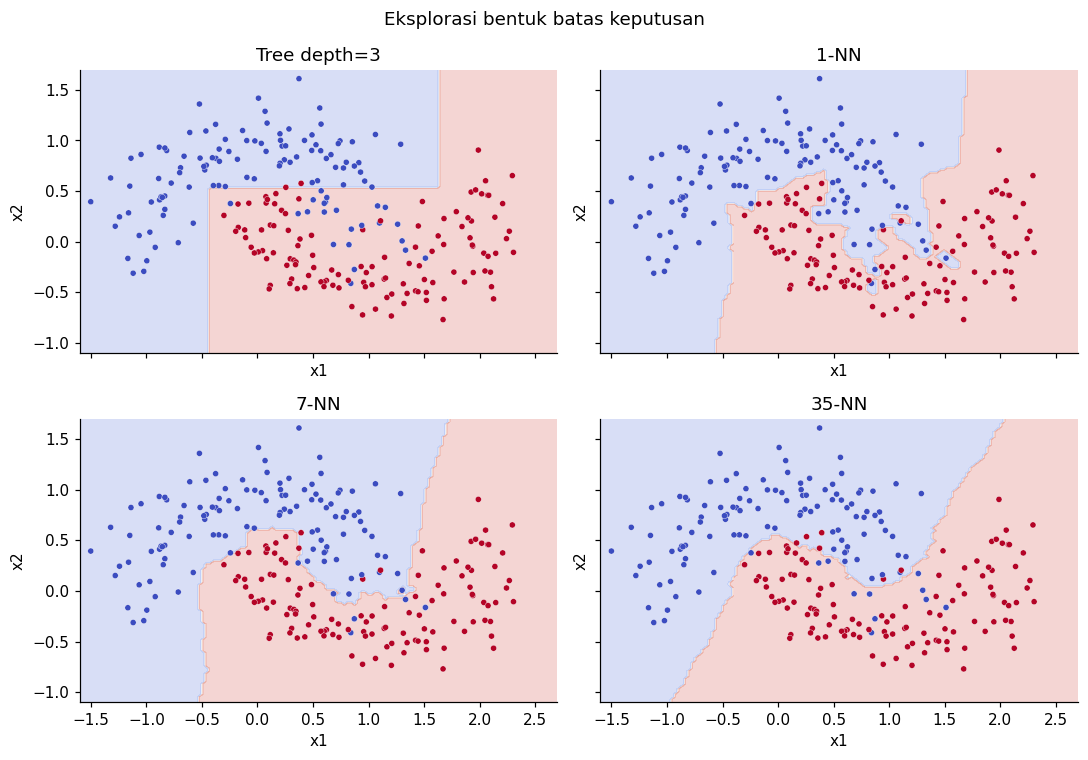

In [11]:
# C11
X_moons, y_moons = make_moons(n_samples=240, noise=0.22, random_state=SEED)
models_geometry = [
    ("Tree depth=3", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    ("1-NN", KNeighborsClassifier(n_neighbors=1)),
    ("7-NN", KNeighborsClassifier(n_neighbors=7)),
    ("35-NN", KNeighborsClassifier(n_neighbors=35))]
gx, gy = np.meshgrid(np.linspace(-1.6,2.7,140), np.linspace(-1.1,1.7,110))
grid = np.column_stack([gx.ravel(), gy.ravel()])
fig, axes = plt.subplots(2,2,figsize=(10,7), sharex=True, sharey=True)
for ax, (name, model) in zip(axes.ravel(), models_geometry):
    model.fit(X_moons, y_moons)
    ax.contourf(gx, gy, model.predict(grid).reshape(gx.shape), alpha=0.22, cmap="coolwarm")
    ax.scatter(X_moons[:,0], X_moons[:,1], c=y_moons, cmap="coolwarm", s=16, edgecolors="white", linewidths=0.25)
    ax.set(title=name, xlabel="x1", ylabel="x2")
fig.suptitle("Eksplorasi bentuk batas keputusan"); fig.tight_layout(); plt.show()

<a id="bab-11"></a>

## 11. Eksperimen yang adil: train, validation/CV, test

1. Pisahkan test sebelum membuat keputusan dari data.
2. Gunakan training fold untuk `fit`, validation fold untuk memilih hyperparameter.
3. Setelah parameter dipilih, latih ulang pada seluruh training set.
4. Buka test set sekali untuk laporan akhir; jangan memakai hasilnya untuk tuning lagi.

$$\widehat{\operatorname{score}}_{CV}=\frac1F\sum_{f=1}^{F}\operatorname{score}_f.$$

`StratifiedKFold` menjaga proporsi kelas kira-kira sama pada setiap fold. Standard deviation antar-fold memperlihatkan variasi split; ini bukan otomatis confidence interval formal.

Dalam kode kita memilih parameter berdasarkan **balanced accuracy**: rata-rata recall setiap kelas. Untuk pencarian grid, seluruh preprocessing harus di dalam pipeline agar validation fold tidak ikut menentukan mean, imputasi, atau komponen PCA.

**Sumber:** trees halaman 16, 21; Telyu slide 17–20. Workflow CV dan Pipeline diperiksa pada dokumentasi resmi scikit-learn.

[Daftar isi](#daftar-isi)

,depth,train,validation,std validation
0,1,0.815625,0.766667,0.062361
1,2,0.906250,0.879167,0.027639
2,3,0.906250,0.879167,0.027639
3,4,0.913542,0.870833,0.027639
4,6,0.977083,0.920833,0.024296
5,10,1.000000,0.912500,0.024296
6,None,1.000000,0.912500,0.024296


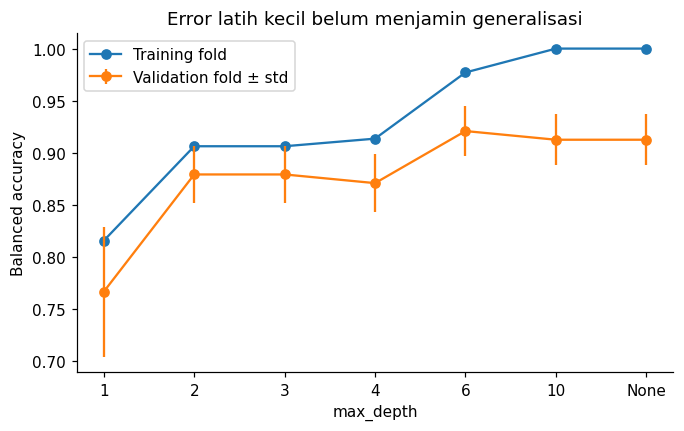

Tree terbaik: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 1} CV: 0.9548
KNN terbaik: {'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'uniform'} CV: 0.9726
Skor 5 fold tree terbaik: [1.         0.9047619  0.91666667 1.         0.95238095]
Mean 5 fold: 0.9547619047619047
Final test disimpan sampai C14; jumlah train/test: 112 38


In [12]:
# C12
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depth_rows = []
for depth in [1,2,3,4,6,10,None]:
    result = cross_validate(DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_moons, y_moons, cv=cv, scoring="balanced_accuracy", return_train_score=True)
    depth_rows.append({"depth": str(depth), "train": result["train_score"].mean(),
                      "validation": result["test_score"].mean(),
                      "std validation": result["test_score"].std()})
depth_df = pd.DataFrame(depth_rows)
display(depth_df)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(depth_df["depth"], depth_df["train"], "o-", label="Training fold")
ax.errorbar(depth_df["depth"], depth_df["validation"], yerr=depth_df["std validation"],
            marker="o", label="Validation fold ± std")
ax.set(xlabel="max_depth", ylabel="Balanced accuracy", title="Error latih kecil belum menjamin generalisasi")
ax.legend(); plt.show()

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target,
    test_size=0.25, random_state=SEED, stratify=iris.target)
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [2,3,None], "min_samples_leaf": [1,3],
     "ccp_alpha": [0.0,0.01,0.03]}, cv=cv, scoring="balanced_accuracy", n_jobs=1)
# Grid alpha tetap: tidak memakai label validation fold untuk menghasilkan kandidat.
knn_pipeline = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])
knn_search = GridSearchCV(knn_pipeline,
    {"knn__n_neighbors": [1,3,5,9], "knn__weights": ["uniform","distance"],
     "knn__p": [1,2]}, cv=cv, scoring="balanced_accuracy", n_jobs=1)
tree_search.fit(X_train, y_train)
knn_search.fit(X_train, y_train)
print("Tree terbaik:", tree_search.best_params_, "CV:", round(tree_search.best_score_,4))
print("KNN terbaik:", knn_search.best_params_, "CV:", round(knn_search.best_score_,4))
cv_tree_scores = np.array([tree_search.cv_results_[f"split{f}_test_score"][tree_search.best_index_]
                           for f in range(cv.get_n_splits())])
print("Skor 5 fold tree terbaik:", cv_tree_scores)
print("Mean 5 fold:", cv_tree_scores.mean())
print("Final test disimpan sampai C14; jumlah train/test:", len(y_train), len(y_test))

<a id="bab-12"></a>

## 12. Membaca metrik, lalu membuka test set

Untuk masalah biner, anggap kelas 1 sebagai positif. Confusion matrix di scikit-learn memakai **baris = label benar**, **kolom = prediksi**:

$$\begin{pmatrix}TN&FP\\FN&TP\end{pmatrix},$$
$$\operatorname{accuracy}=\frac{TP+TN}{N},\quad
\operatorname{precision}=\frac{TP}{TP+FP},\quad
\operatorname{recall}=\frac{TP}{TP+FN},$$
$$F_1=\frac{2TP}{2TP+FP+FN}.$$

**Intuisi:** precision menanyakan berapa prediksi positif yang benar; recall menanyakan berapa anggota kelas positif yang berhasil ditemukan. Kelas langka dapat mendapat recall buruk meski accuracy terlihat tinggi.

Untuk multiclass, hitung metrik per kelas secara one-versus-rest. **Macro F1** merata-ratakan F1 setiap kelas dengan bobot yang sama. **Balanced accuracy** merata-ratakan recall setiap kelas.

C13 adalah contoh angka tetap yang bisa dihitung tangan. C14 memakai model C12 yang parameternya sudah dikunci, serta baseline `DummyClassifier`. C14 juga membongkar satu query test menjadi jalur tree dan jarak tetangga; angkanya dihitung ulang di lampiran Markdown. Hasil Iris kecil ini latihan prosedur; jangan menyimpulkan algoritme terbaik secara universal dari satu split.

[Daftar isi](#daftar-isi)

In [13]:
# C13
cm_manual = np.array([[40,10],[5,45]])
tn, fp, fn, tp = cm_manual.ravel()
metrics_manual = {"accuracy": (tp+tn)/cm_manual.sum(), "precision": tp/(tp+fp),
                  "recall": tp/(tp+fn), "F1": 2*tp/(2*tp+fp+fn)}
print(metrics_manual)
assert np.isclose(metrics_manual["accuracy"], 0.85)
assert np.isclose(metrics_manual["F1"], 6/7)

{'accuracy': np.float64(0.85), 'precision': np.float64(0.8181818181818182), 'recall': np.float64(0.9), 'F1': np.float64(0.8571428571428571)}


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_F1
0,Dummy baseline,0.315789,0.333333,0.105263,0.333333,0.160000
1,Decision Tree,0.894737,0.897436,0.903030,0.897436,0.896825
2,Scaled KNN,0.921053,0.923077,0.937500,0.923077,0.922039


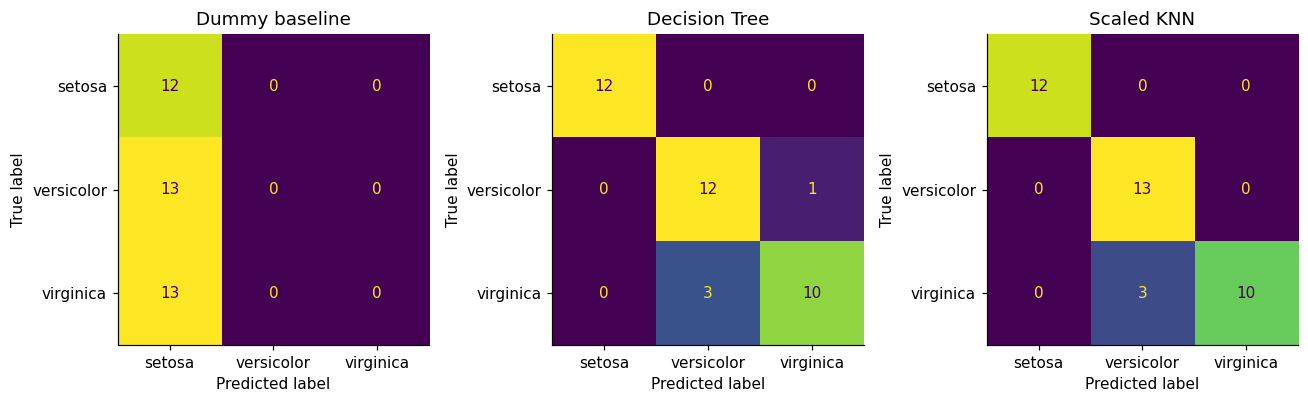

Contoh aturan tree final:
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal length (cm) <= 4.85
|   |   |--- petal width (cm) <= 1.65
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.65
|   |   |   |--- class: 1
|   |--- petal length (cm) >  4.85
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- class: 2

Query pertama: [4.4 3.2 1.3 0.2] label benar: 0
petal length (cm) 1.3 <= 2.449999988079071 → kiri
Probabilitas leaf: [1. 0. 0.]


,fitur,query,mean train,std train,query z
0,sepal length (cm),4.4,5.877679,0.849444,-1.739583
1,sepal width (cm),3.2,3.066071,0.441700,0.303212
2,petal length (cm),1.3,3.764286,1.775772,-1.387726
3,petal width (cm),0.2,1.193750,0.766868,-1.295856


,index train,fitur asli,label,jarak setelah scaling
0,111,"[4.6, 3.2, 1.4, 0.2]",0,0.242089
1,78,"[4.6, 3.1, 1.5, 0.2]",0,0.345509
2,76,"[4.7, 3.2, 1.3, 0.2]",0,0.353172


KNN probability: [1. 0. 0.]


In [14]:
# C14
final_models = {"Dummy baseline": DummyClassifier(strategy="most_frequent").fit(X_train,y_train),
                "Decision Tree": tree_search.best_estimator_, "Scaled KNN": knn_search.best_estimator_}
test_rows = []
fig, axes = plt.subplots(1,3,figsize=(12,3.7))
for ax, (name, model) in zip(axes, final_models.items()):
    pred = model.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test,pred,average="macro",zero_division=0)
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test,pred),
                     "balanced_accuracy": balanced_accuracy_score(y_test,pred),
                     "macro_precision": precision, "macro_recall": recall, "macro_F1": f1})
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred,labels=[0,1,2]),
                           display_labels=iris.target_names).plot(ax=ax,colorbar=False)
    ax.set_title(name)
display(pd.DataFrame(test_rows))
fig.tight_layout(); plt.show()
print("Contoh aturan tree final:")
print(export_text(tree_search.best_estimator_, feature_names=list(iris.feature_names)))

# Bongkar satu prediksi aktual; parameter sudah dipilih, bukan tuning pada test.
q_iris_demo = X_test[0]
tree_demo = tree_search.best_estimator_
print("Query pertama:", q_iris_demo, "label benar:", y_test[0])
for node in tree_demo.decision_path([q_iris_demo]).indices:
    feature = tree_demo.tree_.feature[node]
    if feature >= 0:
        threshold = tree_demo.tree_.threshold[node]
        print(iris.feature_names[feature], q_iris_demo[feature], "<=", threshold,
              "→ kiri" if q_iris_demo[feature] <= threshold else "→ kanan")
print("Probabilitas leaf:", tree_demo.predict_proba([q_iris_demo])[0])
scale_demo = knn_search.best_estimator_.named_steps["scale"]
knn_demo = knn_search.best_estimator_.named_steps["knn"]
qz_demo = scale_demo.transform([q_iris_demo])
display(pd.DataFrame({"fitur": iris.feature_names, "query": q_iris_demo,
    "mean train": scale_demo.mean_, "std train": scale_demo.scale_, "query z": qz_demo[0]}))
dist_demo, idx_demo = knn_demo.kneighbors(qz_demo)
display(pd.DataFrame({"index train": idx_demo[0], "fitur asli": list(X_train[idx_demo[0]]),
    "label": y_train[idx_demo[0]], "jarak setelah scaling": dist_demo[0]}))
print("KNN probability:", knn_search.best_estimator_.predict_proba([q_iris_demo])[0])

---
### Tingkat Lanjutan — Bab 13–20

Tujuan belajar: mempelajari twoing, prior kelas, dan biaya kesalahan; missing values dan surrogate split; curse of dimensionality dan PCA; dua kasus sumber (digit tujuh segmen dan waveform); oblique split; perluasan ke regresi; serta perbandingan mekanisme dan biaya komputasi.

[Kembali ke Daftar Isi](#daftar-isi)

<a id="bab-13"></a>

## 13. Twoing, prior kelas, dan biaya kesalahan

### 13.1 Twoing: bedakan komposisi dua anak

Twoing memberi nilai besar jika kedua anak cukup besar dan distribusi kelasnya berbeda:

$$\operatorname{Twoing}(s,t)=\frac{p_Lp_R}{4}
\left[\sum_{j=1}^{K}|p_j(t_L)-p_j(t_R)|\right]^2.$$

Contoh: $p_L=p_R=0.5$, kiri $(0.8,0.2,0)$, kanan $(0,0.2,0.8)$. Jumlah selisih absolut 1.6; skor twoing $=0.16$. Gini gain contoh ini $=0.32$, karena ukuran skor kedua kriteria berbeda.

`DecisionTreeClassifier` tidak menyediakan `criterion='twoing'`. C06 menghitung skor manual; pohon pustaka di notebook memakai Gini atau entropy.

### 13.2 Ketika prior berbeda dari proporsi data latih

Data latih mungkin sengaja mengandung banyak sampel kelas langka. Misalkan jumlah latih per kelas $N_j$, jumlah kelas itu di node $N_j(t)$, dan prior yang ingin kita gunakan $\pi_j$:

$$p(t\mid j)=\frac{N_j(t)}{N_j},\quad p(j,t)=\pi_jp(t\mid j),$$
$$p(t)=\sum_jp(j,t),\qquad p(j\mid t)=\frac{p(j,t)}{p(t)}.$$

Jika $\pi_j=N_j/N$, ini kembali menjadi $N_j(t)/N(t)$. Mengubah prior seperti ini mengasumsikan distribusi fitur **di dalam setiap kelas** tetap relevan; ini bukan izin mengubah prior sembarangan. `class_weight` mengubah bobot belajar, tetapi tidak otomatis menjamin probabilitas terkalibrasi pada prior baru.

### 13.3 Kelas mayoritas belum tentu keputusan berbiaya terendah

Dengan matriks biaya $C(a,j)$ untuk memprediksi $a$ ketika kelas benar $j$:

$$a^*=\arg\min_a\sum_j C(a,j)p(j\mid t).$$

Jika false negative berbiaya 5 dan false positive berbiaya 1, pilih kelas 1 ketika $q=P(y=1\mid x)>1/6$. Aturan 0.5 hanya cocok untuk biaya salah klasifikasi yang simetris.

**Sumber:** trees halaman 9–13. Matriks biaya adalah pengembangan dari aturan 0–1 loss.

[Daftar isi](#daftar-isi)

In [15]:
# C06
def twoing(p_left, p_right, prob_left):
    return prob_left*(1-prob_left)/4 * np.abs(np.array(p_left)-np.array(p_right)).sum()**2

twoing_score = twoing([0.8, 0.2, 0], [0, 0.2, 0.8], 0.5)
assert np.isclose(twoing_score, 0.16)
print("Twoing:", twoing_score)

class_totals = np.array([80, 20])
class_in_node = np.array([8, 12])
priors = np.array([0.5, 0.5])
p_node_given_class = class_in_node / class_totals
joint = priors * p_node_given_class
posterior = joint / joint.sum()
display(pd.DataFrame({"kelas": [0, 1], "p(t|j)": p_node_given_class,
    "p(j,t)": joint, "p(j|t), prior baru": posterior,
    "p(j|t), prior empiris": class_in_node/class_in_node.sum()}))
assert np.allclose(posterior, [1/7, 6/7])
q_cost = 0.25
risk_predict0 = 5*q_cost
risk_predict1 = 1*(1-q_cost)
print("Risiko prediksi 0:", risk_predict0, "| prediksi 1:", risk_predict1)
print("Keputusan biaya minimum:", int(risk_predict1 < risk_predict0))

Twoing: 0.16000000000000003


,kelas,p(t|j),"p(j,t)","p(j|t), prior baru","p(j|t), prior empiris"
0,0,0.1,0.05,0.142857,0.4
1,1,0.6,0.30,0.857143,0.6


Risiko prediksi 0: 1.25 | prediksi 1: 0.75
Keputusan biaya minimum: 1


<a id="bab-14"></a>

## 14. Missing values, kategori, dan surrogate split

Jika setiap fitur hilang dengan peluang 5% secara independen dan ada 50 fitur:

$$P(\text{minimal satu hilang})=1-(1-0.05)^{50}\approx0.9231.$$

Jadi missing value bukan kejadian langka pada data dengan banyak kolom. **Imputation** mengisi nilai, misalnya median untuk fitur numerik. **Surrogate split** mencari pertanyaan pada fitur lain yang meniru arah kiri/kanan split utama saat fitur utama hilang. Ini dua mekanisme berbeda.

C15 menunjukkan kesepakatan arah split pada contoh kecil. Kesepakatan perlu dibandingkan dengan strategi selalu memilih cabang mayoritas; jika 95% sampel masuk kiri, meniru semua ke kiri memberi agreement 95% tanpa informasi baru. Surrogate sebenarnya dipelajari dari sampel dengan kedua fitur tersedia; kode ini hanya demonstrasi satu kandidat.

C16 memakai `ColumnTransformer`: numerik diimputasi dan distandardisasi, kategori diimputasi dan di-one-hot. Semua `fit` di training data. Dukungan missing value tree tergantung estimator, kriteria, dan versi; pipeline eksplisit ini memberikan perilaku yang jelas, termasuk untuk KNN.

**Sumber:** trees halaman 5 dan 25. Preprocessing campuran adalah pengembangan praktis.

[Daftar isi](#daftar-isi)

In [16]:
# C15
prob_any_missing = 1-0.95**50
print("P minimal satu fitur hilang:", prob_any_missing)
assert np.isclose(prob_any_missing, 0.9230550247232868)
primary_values = np.array([1,2,3,7,8,9])
other_values = np.array([10,20,60,70,80,90])
primary_left = primary_values <= 5
surrogate_left = other_values <= 50
agreement = np.mean(primary_left == surrogate_left)
baseline_agreement = max(primary_left.mean(), 1-primary_left.mean())
adjusted_agreement = (agreement-baseline_agreement)/(1-baseline_agreement)
print("Agreement kandidat:", agreement, "baseline:", baseline_agreement,
      "adjusted:", adjusted_agreement)

P minimal satu fitur hilang: 0.9230550247232868
Agreement kandidat: 0.8333333333333334 baseline: 0.5 adjusted: 0.6666666666666667


In [17]:
# C16
mixed_train = pd.DataFrame({"umur": [20,35,np.nan,50,27,44],
    "pendapatan": [2.,5.,3.,8.,np.nan,6.],
    "status": ["pelajar","pegawai","pelajar","pegawai",np.nan,"wirausaha"]})
mixed_y = np.array([0,1,0,1,0,1])
mixed_query = pd.DataFrame({"umur": [np.nan], "pendapatan": [4.], "status": ["baru"]})
numeric = Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())])
categorical = Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                        ("encode",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
preprocess = ColumnTransformer([("num",numeric,["umur","pendapatan"]),
                               ("cat",categorical,["status"])])
mixed_model = Pipeline([("prepare",preprocess),("knn",KNeighborsClassifier(n_neighbors=3))])
mixed_model.fit(mixed_train,mixed_y)
print("Prediksi query dengan missing value dan kategori baru:", mixed_model.predict(mixed_query))
print("Probabilitas:", mixed_model.predict_proba(mixed_query))
print("Fitur hasil encoding:", mixed_model.named_steps["prepare"].get_feature_names_out())
print("Ini demonstrasi preprocessing, bukan evaluasi akurasi dengan 6 sampel.")

Prediksi query dengan missing value dan kategori baru: [0]
Probabilitas: [[0.66666667 0.33333333]]
Fitur hasil encoding: ['num__umur' 'num__pendapatan' 'cat__status_pegawai' 'cat__status_pelajar'
 'cat__status_wirausaha']
Ini demonstrasi preprocessing, bukan evaluasi akurasi dengan 6 sampel.


<a id="bab-15"></a>

## 15. Curse of dimensionality dan PCA

Semakin banyak dimensi, semakin sulit mengumpulkan contoh yang benar-benar dekat. Jika setiap sisi sebuah kotak lokal menempati fraksi $a$ dari rentang fitur, fraksi volumenya adalah $a^d$. Untuk $a=0.5,d=10$, volume hanya $1/1024$.

Untuk dua titik independen dengan setiap koordinat uniform di $[0,1]$:

$$E[\|\mathbf X-\mathbf Y\|^2]=d/6.$$

C17 menggambar jarak yang dibagi $\sqrt{d/6}$. Ini ukuran skala, **bukan** persamaan $E[\|X-Y\|]=\sqrt{d/6}$. Pada simulasi dimensi lebih tinggi, jarak relatif makin terkonsentrasi. Ini dapat mengurangi informasi dari perbedaan tetangga dekat dan jauh, terutama ketika banyak fitur tidak relevan.

PCA memproyeksikan fitur ke arah variasi terbesar:

$$\mathbf z=W^T(\mathbf x-\boldsymbol\mu).$$

Variansi besar tidak selalu paling berguna untuk membedakan kelas. PCA bukan obat universal. Jika dipakai saat CV, PCA harus berada di pipeline; kita mencobanya di kasus waveform C19.

**Sumber:** Telyu slide 34, 36; PCA adalah pengembangan opsional untuk eksperimen lanjutan.

[Daftar isi](#daftar-isi)

,dimensi,mean jarak kuadrat,teori d/6,std/mean jarak
0,2,0.338349,0.333333,0.486707
1,10,1.682013,1.666667,0.191839
2,50,8.327406,8.333333,0.084772
3,200,33.336778,33.333333,0.041865


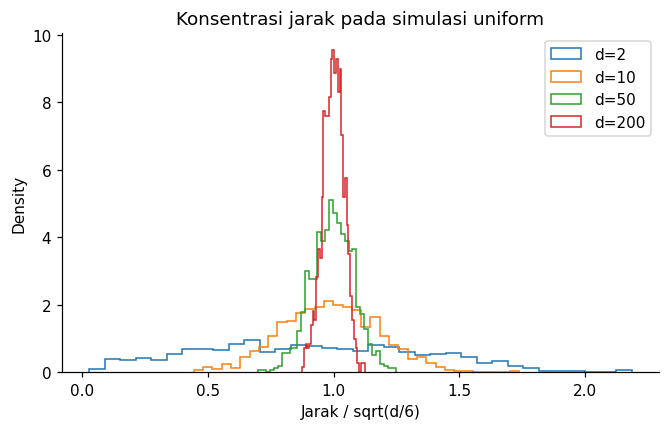

Volume relatif a=0.5, d=10: 0.0009765625


In [18]:
# C17
rng_dim = np.random.default_rng(SEED)
dim_rows = []
fig, ax = plt.subplots(figsize=(7,4))
for d in [2,10,50,200]:
    A = rng_dim.uniform(size=(1000,d))
    B = rng_dim.uniform(size=(1000,d))
    distances = np.linalg.norm(A-B,axis=1)
    dim_rows.append({"dimensi": d, "mean jarak kuadrat": np.mean(distances**2),
                     "teori d/6": d/6, "std/mean jarak": distances.std()/distances.mean()})
    ax.hist(distances/np.sqrt(d/6),bins=35,density=True,histtype="step",label=f"d={d}")
display(pd.DataFrame(dim_rows))
ax.set(xlabel="Jarak / sqrt(d/6)", ylabel="Density", title="Konsentrasi jarak pada simulasi uniform")
ax.legend(); plt.show()
print("Volume relatif a=0.5, d=10:", 0.5**10)

<a id="bab-16"></a>

## 16. Kasus sumber: digit tujuh segmen yang rusak

trees.pdf merepresentasikan digit 0–9 sebagai 7 bit lampu. Setiap lampu secara independen terbalik dengan peluang $\eta=0.1$. Ini klasifikasi multiclass dengan noise nyata pada fitur, bukan sekadar label salah.

$$\mathbf x=\mathbf b_y\oplus\mathbf e,\qquad e_j\sim\operatorname{Bernoulli}(0.1).$$

Jika observed digit berbeda dari template digit $c$ pada $m$ posisi:

$$P(\mathbf x\mid y=c)=\eta^m(1-\eta)^{7-m}.$$

Dengan prior kelas seragam, classifier Bayes untuk pembangkit ini memilih template dengan likelihood terbesar (setara jarak Hamming terkecil). Untuk query semua lampu menyala, likelihood digit 8 adalah $0.9^7$, sedangkan digit 9 adalah $0.1\times0.9^6$; rasionya 9.

C18 memakai tabel template persis dari halaman 15, 200 sampel latih, dan 5000 sampel uji **baru**. Tree Gini dipilih lewat CV. Sumber memakai twoing dan setup historis; karena kriterianya berbeda, angka hasil kita bukan reproduksi persis laporan sumber. Rule Bayes di sini mengetahui pembangkit sintetis; itu pembanding oracle, bukan model yang belajar dari 200 sampel.

**Sumber:** trees halaman 15–17.

[Daftar isi](#daftar-isi)

In [19]:
# C18
# Urutan segmen mengikuti trees.pdf halaman 15, bukan penomoran library display lain.
segment_templates = np.array([
    [1,1,1,0,1,1,1],  # 0
    [0,0,1,0,0,1,0],  # 1
    [1,0,1,1,1,0,1],  # 2
    [1,0,1,1,0,1,1],  # 3
    [0,1,1,1,0,1,0],  # 4
    [1,1,0,1,0,1,1],  # 5
    [1,1,0,1,1,1,1],  # 6
    [1,0,1,0,0,1,0],  # 7
    [1,1,1,1,1,1,1],  # 8
    [1,1,1,1,0,1,1]   # 9
])
def make_segment_data(n, seed, noise=0.1):
    rng = np.random.default_rng(seed)
    y = rng.integers(0,10,size=n)
    flips = rng.random((n,7)) < noise
    return np.logical_xor(segment_templates[y],flips).astype(int), y

X_digit_train,y_digit_train = make_segment_data(200,SEED)
X_digit_test,y_digit_test = make_segment_data(5000,SEED+1)
digit_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [4,6,None], "ccp_alpha": [0,0.005,0.01]},cv=cv,scoring="accuracy",n_jobs=1)
digit_search.fit(X_digit_train,y_digit_train)
digit_pred = digit_search.predict(X_digit_test)
hamming_counts = (X_digit_test[:,None,:] != segment_templates[None,:,:]).sum(axis=2)
bayes_pred = np.argmax(hamming_counts*np.log(0.1)+(7-hamming_counts)*np.log(0.9),axis=1)
print("Parameter tree:", digit_search.best_params_)
print("CV error tree:", 1-digit_search.best_score_)
print("Final test error tree:", 1-accuracy_score(y_digit_test,digit_pred))
print("Monte Carlo test error rule Bayes:", 1-accuracy_score(y_digit_test,bayes_pred))
all_on = np.ones(7,dtype=int)
m_all_on = (segment_templates != all_on).sum(axis=1)
likelihood_all_on = 0.1**m_all_on * 0.9**(7-m_all_on)
display(pd.DataFrame({"digit": range(10), "mismatch query semua menyala": m_all_on,
                     "likelihood": likelihood_all_on}))
assert np.isclose(likelihood_all_on[8]/likelihood_all_on[9],9)

Parameter tree: {'ccp_alpha': 0.005, 'max_depth': 6}
CV error tree: 0.275
Final test error tree: 0.3054
Monte Carlo test error rule Bayes: 0.26480000000000004


,digit,mismatch query semua menyala,likelihood
0,0,1,0.053144
1,1,5,0.000008
2,2,2,0.005905
3,3,2,0.005905
4,4,3,0.000656
5,5,2,0.005905
6,6,1,0.053144
7,7,4,0.000073
8,8,0,0.478297
9,9,1,0.053144


<a id="bab-17"></a>

## 17. Kasus sumber: waveform dengan 21 fitur

Tiga fungsi segitiga saling bergeser. **Label pada gambar sumber perlu dibaca hati-hati:** pusat $h_1$ di 7, $h_2$ di 15, dan $h_3$ di 11, bukan urutan kiri-ke-kanan 1,2,3.

$$h_c(j)=\max(6-|j-\mu_c|,0),\quad (\mu_1,\mu_2,\mu_3)=(7,15,11).$$

Untuk label kelas 1, campurkan $h_1,h_2$; kelas 2 campurkan $h_1,h_3$; kelas 3 campurkan $h_2,h_3$:

$$x_j=u h_a(j)+(1-u)h_b(j)+\epsilon_j,\quad
u\sim U(0,1),\quad\epsilon_j\sim\mathcal N(0,1),\quad j=1,\ldots,21.$$

Saat $u=0.25$ dan $\epsilon=0$, nilai kelas 1 pada $j=7$ adalah 1.5; pada $j=15$ adalah 4.5. Noise menambah variasi sehingga contoh kelas yang sama tidak identik.

C19 membuat 300 sampel latih dan 1000 uji, memilih tree dan KNN+PCA lewat CV pada training data, lalu mengevaluasi sekali. Kode memakai label 0,1,2 untuk kelas sumber 1,2,3. PCA 95% dipilih sebagai konfigurasi eksplorasi, bukan hasil bahwa PCA selalu meningkatkan performa. Angka Bayes error waveform pada sumber tidak dihitung ulang di sini.

**Sumber:** trees halaman 18–21. PCA dan KNN pada waveform adalah perluasan notebook.

[Daftar isi](#daftar-isi)

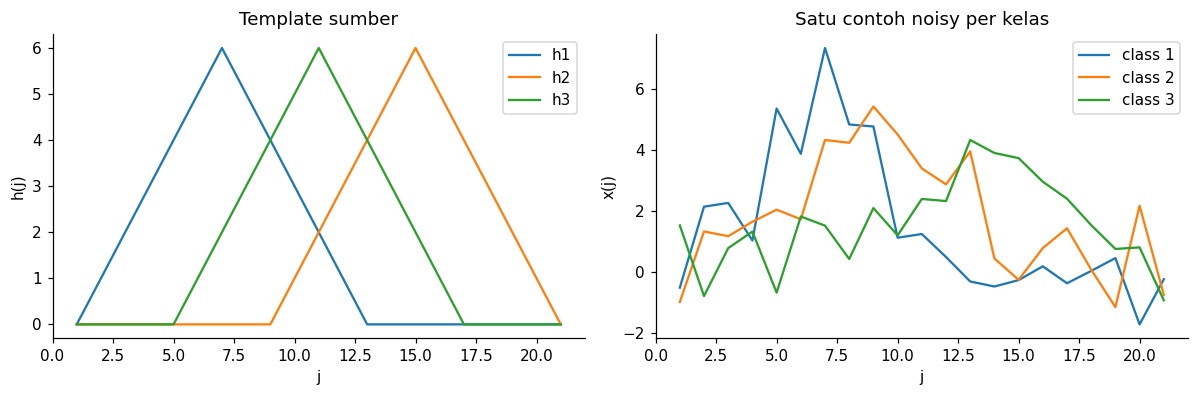

,model,CV balanced accuracy,final test balanced accuracy,parameter
0,Tree,0.745317,0.693090,"{'max_depth': 3, 'min_samples_leaf': 8}"
1,Scaled KNN + PCA 95%,0.852181,0.805174,{'knn__n_neighbors': 15}


Dimensi PCA terpilih saat refit seluruh train: 17


In [20]:
# C19
wave_j = np.arange(1,22)
wave_templates = np.maximum(6-np.abs(wave_j[None,:]-np.array([7,15,11])[:,None]),0)
wave_pairs = np.array([[0,1],[0,2],[1,2]])
def make_wave_data(n, seed):
    rng = np.random.default_rng(seed)
    y = rng.integers(0,3,size=n)
    u = rng.uniform(size=(n,1))
    pairs = wave_pairs[y]
    X = u*wave_templates[pairs[:,0]]+(1-u)*wave_templates[pairs[:,1]]+rng.normal(size=(n,21))
    return X,y

noiseless_example = 0.25*wave_templates[0]+0.75*wave_templates[1]
assert np.isclose(noiseless_example[6],1.5) and np.isclose(noiseless_example[14],4.5)
X_wave_train,y_wave_train = make_wave_data(300,SEED+2)
X_wave_test,y_wave_test = make_wave_data(1000,SEED+3)
fig, axes = plt.subplots(1,2,figsize=(11,3.7))
for i,h in enumerate(wave_templates): axes[0].plot(wave_j,h,label=f"h{i+1}")
for c in range(3): axes[1].plot(wave_j,X_wave_train[np.flatnonzero(y_wave_train==c)[0]],label=f"class {c+1}")
axes[0].set(title="Template sumber",xlabel="j",ylabel="h(j)"); axes[0].legend()
axes[1].set(title="Satu contoh noisy per kelas",xlabel="j",ylabel="x(j)"); axes[1].legend()
fig.tight_layout(); plt.show()
wave_tree = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [3,6,None],"min_samples_leaf": [2,8]},cv=cv,scoring="balanced_accuracy",n_jobs=1)
wave_knn = GridSearchCV(Pipeline([("scale",StandardScaler()),("pca",PCA(n_components=0.95)),
    ("knn",KNeighborsClassifier())]), {"knn__n_neighbors": [3,7,15]},
    cv=cv,scoring="balanced_accuracy",n_jobs=1)
wave_rows=[]
for name,search in [("Tree",wave_tree),("Scaled KNN + PCA 95%",wave_knn)]:
    search.fit(X_wave_train,y_wave_train)
    pred=search.predict(X_wave_test)
    wave_rows.append({"model":name,"CV balanced accuracy":search.best_score_,
                      "final test balanced accuracy":balanced_accuracy_score(y_wave_test,pred),
                      "parameter":str(search.best_params_)})
display(pd.DataFrame(wave_rows))
print("Dimensi PCA terpilih saat refit seluruh train:",wave_knn.best_estimator_.named_steps["pca"].n_components_)

<a id="bab-18"></a>

## 18. Oblique split: satu garis miring atau banyak tangga?

Split biasa hanya memakai satu fitur, misalnya $x_1\le c$. Jika batas sesungguhnya miring, banyak split diperlukan untuk membuat pendekatan tangga. **Oblique split** memakai kombinasi linear:

$$\sum_{j=1}^{p}a_jx_j\le c.$$

C20 membuat label $y=\mathbf1[x_1+x_2>0]$. Stump pada fitur baru $z=x_1+x_2$ cukup untuk memisahkan data ini. Koefisien `[1,1]` diketahui dari pembangkit; kode tidak mengimplementasikan algoritme optimasi oblique tree seperti OC1. Ini demonstrasi representasi, bukan hasil generalisasi atau kompetisi model.

Komputasi untuk mencari koefisien secara otomatis lebih mahal, dan aturan dapat lebih sulit dijelaskan. `DecisionTreeClassifier` standar tetap axis-aligned pada fitur yang diterimanya.

**Sumber:** trees halaman 24; Telyu slide 21, 23–24.

[Daftar isi](#daftar-isi)

Agreement training axis tree depth 2: 0.92
Agreement training stump pada z=x1+x2: 1.0


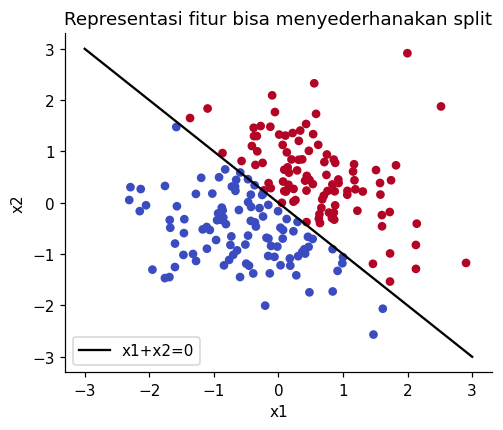

In [21]:
# C20
rng_oblique=np.random.default_rng(SEED)
X_oblique=rng_oblique.normal(size=(200,2))
y_oblique=(X_oblique.sum(axis=1)>0).astype(int)
axis_model=DecisionTreeClassifier(max_depth=2,random_state=SEED).fit(X_oblique,y_oblique)
z_oblique=X_oblique.sum(axis=1,keepdims=True)
oblique_stump=DecisionTreeClassifier(max_depth=1,random_state=SEED).fit(z_oblique,y_oblique)
print("Agreement training axis tree depth 2:",axis_model.score(X_oblique,y_oblique))
print("Agreement training stump pada z=x1+x2:",oblique_stump.score(z_oblique,y_oblique))
fig,ax=plt.subplots(figsize=(5,4))
ax.scatter(X_oblique[:,0],X_oblique[:,1],c=y_oblique,cmap="coolwarm",s=22)
line=np.linspace(-3,3,100);ax.plot(line,-line,color="black",label="x1+x2=0")
ax.set(xlabel="x1",ylabel="x2",title="Representasi fitur bisa menyederhanakan split")
ax.legend();plt.show()

<a id="bab-19"></a>

## 19. Perluasan: tree dan KNN untuk regresi

Materi utama sumber adalah klasifikasi. Untuk target numerik, prediksi leaf tree dapat berupa mean target, sedangkan KNN melakukan rata-rata target tetangga.

$$\hat y_{\text{tree}}(x)=\frac1{N_t}\sum_{i\in t}y_i,\qquad
\hat y_{\text{KNN}}(x)=\frac{\sum_{i\in\mathcal N_k}w_iy_i}{\sum_{i\in\mathcal N_k}w_i}.$$

Kriteria *squared error* meminimalkan penyebaran nilai target:

$$\operatorname{SSE}(t)=\sum_{i\in t}(y_i-\bar y_t)^2,\qquad
\operatorname{MSE}(t)=\operatorname{SSE}(t)/N_t.$$

Untuk $x=[1,2,3,4]$ dan $y=[1,2,8,9]$, mean parent 5 dan SSE parent 50. Split di 2.5 menghasilkan mean 1.5 dan 8.5, total SSE anak 1. MSE parent 12.5, MSE sesudah split 0.25, gain 12.25.

Tree memprediksi konstan per leaf dan KNN bergantung pada target tetangga; keduanya punya keterbatasan untuk mengekstrapolasi jauh di luar rentang data latih.

[Daftar isi](#daftar-isi)

In [22]:
# C21
X_reg=np.array([[1.],[2.],[3.],[4.]])
y_reg=np.array([1.,2.,8.,9.])
parent_mean=y_reg.mean()
parent_sse=np.sum((y_reg-parent_mean)**2)
left_reg=X_reg[:,0]<=2.5
child_sse=sum(np.sum((values-values.mean())**2) for values in [y_reg[left_reg],y_reg[~left_reg]])
print("Mean parent:",parent_mean,"SSE parent:",parent_sse,"SSE anak:",child_sse)
print("MSE gain:",(parent_sse-child_sse)/len(y_reg))
reg_tree=DecisionTreeRegressor(max_depth=1,random_state=SEED).fit(X_reg,y_reg)
reg_knn=KNeighborsRegressor(n_neighbors=2).fit(X_reg,y_reg)
display(pd.DataFrame({"query":[1.6,3.6],"tree":reg_tree.predict([[1.6],[3.6]]),
                      "KNN k=2":reg_knn.predict([[1.6],[3.6]])}))
assert parent_sse==50 and child_sse==1
assert np.allclose(reg_tree.predict([[1.6],[3.6]]),[1.5,8.5])

Mean parent: 5.0 SSE parent: 50.0 SSE anak: 1.0
MSE gain: 12.25


,query,tree,KNN k=2
0,1.6,1.5,1.5
1,3.6,8.5,8.5


<a id="bab-20"></a>

## 20. Membandingkan mekanisme dan biaya komputasi

| Pertanyaan | Decision Tree | KNN |
|---|---|---|
| Apa yang disimpan? | aturan split dan statistik leaf | contoh latih dan mungkin indeks |
| Kapan pekerjaan utama dilakukan? | saat membangun pohon | banyak pekerjaan saat mencari tetangga |
| Prediksi satu objek | kira-kira $O(D)$ untuk kedalaman $D$ | brute force jarak $O(Np)$, lalu pemilihan tetangga |
| Bentuk batas | sejajar sumbu untuk split standar | bergantung pada data dan metrik |
| Parameter penting | depth, leaf size, impurity, alpha | k, weights, metrik, preprocessing |
| Scaling numerik | umumnya tidak diperlukan | sering sangat penting |
| Mudah dijelaskan? | jalur aturan pada tree kecil | contoh tetangga dan kontribusi jaraknya |
| Risiko | pohon tidak stabil/terlalu rumit | jarak menyesatkan, banyak fitur tidak relevan |

Pohon seimbang sering punya $D\approx\log N$, tetapi pohon tidak seimbang bisa jauh lebih dalam. KNN dapat menggunakan indeks KD-tree/Ball-tree; keuntungan pencarian bergantung pada dimensi dan data. Jumlah sampel, fitur, dan struktur model menentukan biaya, bukan label eager/lazy saja.

**Catatan sumber yang diperjelas:**

- `I=L-1` berlaku untuk full binary tree, bukan semua nonbinary tree (Telyu slide 9–10).
- Overfitting biasanya berarti terlalu sesuai dengan data latih; memakai test berulang untuk tuning juga bisa mengoverfit proses evaluasi (slide 16, 19).
- `fit` KNN tidak selalu nol komputasi (Week3 halaman 10).
- Batas KNN dapat tidak mulus; k lebih besar tidak menjamin kurva matematis yang mulus (Week3 halaman 10).
- Tree klasik dapat memakai kategori/surrogate; fitur itu tidak otomatis tersedia dengan perilaku yang sama pada setiap pustaka.

**Sumber:** trees halaman 23–25; Telyu slide 22–23, 35; Week3 halaman 10–11.

[Daftar isi](#daftar-isi)

---
### Latihan dan Referensi — Bab 21–23

Tujuan belajar: memeriksa intuisi lewat delapan pertanyaan, meninjau ringkasan persamaan beserta panduan langkah berikutnya, dan menelusuri peta sumber serta rujukan implementasi.

[Kembali ke Daftar Isi](#daftar-isi)

<a id="bab-21"></a>

## 21. Delapan pertanyaan untuk memeriksa intuisi

Jawab sebelum membuka kode jawaban C22 dan pembahasan di file hitungan manual.

1. Node berisi 3 kelas 0 dan 1 kelas 1. Berapa Gini, entropy, dan error?
2. Untuk C01, berapa Gini gain threshold 1.5? Mengapa kalah dari 2.5?
3. Jika gain lokal 0.25 terjadi pada node dengan $p(t)=0.2$, berapa gain global?
4. Untuk C08, apa hasil uniform voting $k=2$ dan apa kebijakan saat seri?
5. Kapan scaling kecil C10 mengganti tetangga terdekat?
6. Jika false negative berbiaya 5 dan false positive 1, keputusan mana untuk $P(y=1)=0.20$?
7. Dalam C19, kelas sumber 1 tanpa noise dengan $u=0.25$: berapa nilai pada $j=11$?
8. Kenapa accuracy latih 1.0 tidak cukup untuk menyatakan model bagus?

**Eksperimen lanjutan yang bisa kamu coba:** ubah noise `make_moons`, bandingkan entropy vs Gini dengan CV, tambahkan 20 fitur noise ke data KNN, atau ganti PCA 95% dengan tanpa PCA. Ubah satu hal setiap kali dan gunakan validation/CV untuk mengambil keputusan. Jangan tuning lagi memakai test lama; jika banyak iterasi, siapkan evaluasi baru yang benar-benar belum dipakai.

[Daftar isi](#daftar-isi)

In [23]:
# C22
answers={
    "1": {c:impurity([0,0,0,1],c) for c in ["gini","entropy","error"]},
    "2": float(split_gini.query("threshold==1.5").iloc[0]["gain"]),
    "3": 0.2*0.25,
    "4": knn_manual(X_neighbors,y_neighbors,query,k=2)[0],
    "5": "mentah B; setelah scaling A",
    "6": 1 if 5*0.20 > 1*(1-0.20) else 0,
    "7": float(noiseless_example[10]),
    "8": "model bisa menghafal; ukur validation/CV dan final test yang terpisah"
}
for key,value in answers.items(): print(key,"→",value)
assert np.isclose(answers["2"],0.1)
assert np.isclose(answers["3"],0.05)
assert answers["4"]==0 and answers["6"]==1
assert np.isclose(answers["7"],2.0)
print("Pemeriksaan angka kecil selesai.")

1 → {'gini': 0.375, 'entropy': 0.8112781244591328, 'error': 0.25}
2 → 0.10000000000000003
3 → 0.05
4 → 0
5 → mentah B; setelah scaling A
6 → 1
7 → 2.0
8 → model bisa menghafal; ukur validation/CV dan final test yang terpisah
Pemeriksaan angka kecil selesai.


<a id="bab-22"></a>

## 22. Ringkasan persamaan dan panduan memilih langkah berikut

| Yang ingin dijelaskan | Persamaan inti | Kode |
|---|---|---|
| Campuran kelas | $G=1-\sum_jp_j^2$, $H=-\sum_jp_j\log_2p_j$ | C03 |
| Split terbaik | $\Delta i=i(t)-p_Li(t_L)-p_Ri(t_R)$ | C04–C05 |
| Pengurangan seluruh pohon | $\Delta I=p(t)\Delta i$ | C04 |
| Twoing | $p_Lp_R(\sum_j|p_{jL}-p_{jR}|)^2/4$ | C06 |
| Posterior dengan prior baru | $p(j\mid t)\propto\pi_jN_j(t)/N_j$ | C06 |
| Biaya keputusan | $a^*=\arg\min_a\sum_j C(a,j)p(j\mid t)$ | C06 |
| Pruning | $R_\alpha(T)=R(T)+\alpha L$ | C07, C12 |
| Jarak dan voting KNN | $d_2=\sqrt{\sum_j(x_j-q_j)^2}$, voting | C08–C09 |
| Scaling | $z_j=(x_j-\mu_j)/\sigma_j$ | C10 |
| Evaluasi | confusion matrix, precision, recall, F1 | C13–C14 |
| Missing value | $P(\text{ada hilang})=1-(1-q)^d$ | C15–C16 |
| Dimensi tinggi | $E[\|X-Y\|^2]=d/6$ | C17 |
| Noise tujuh segmen | $P(x\mid c)=\eta^m(1-\eta)^{7-m}$ | C18 |
| Waveform | $x_j=u h_a(j)+(1-u)h_b(j)+\epsilon_j$ | C19 |
| Oblique | $\sum_ja_jx_j\le c$ | C20 |
| Regresi | mean leaf / mean tetangga; SSE | C21 |

Jika hitungan C03–C10 sudah masuk akal, lanjutkan ke prosedur CV C12–C14. Setelah itu, gunakan kasus digit/waveform untuk menguji pemahaman pada data yang lebih sulit. Model terbaik ditentukan oleh tujuan, data, biaya kesalahan, dan evaluasi yang tepat.

[Daftar isi](#daftar-isi)

<a id="bab-23"></a>

## 23. Peta sumber dan rujukan implementasi

| Sumber asli | Bagian yang dipakai | Bagian notebook |
|---|---|---|
| `trees.pdf`, hlm. 1–5 | bentuk tree, notasi, split numerik/kategori | 1–2, 4–5, 8 |
| `trees.pdf`, hlm. 6–14 | impurity lokal/global, twoing, prior, stopping, class assignment, error | 3–6, 13 |
| `trees.pdf`, hlm. 15–17 | digit tujuh segmen dan noise | 16 |
| `trees.pdf`, hlm. 18–22 | waveform dan klasifikasi | 17 |
| `trees.pdf`, hlm. 23–25 | kelebihan, linear combination, missing/surrogate | 9, 14, 18, 20 |
| `Telyu-03.pptx`, slide 4–24 | decision rules, geometri, pruning, keterbatasan | 2–6, 10–11, 18, 20 |
| `Telyu-03.pptx`, slide 26–35 | 1-NN, metrik, scaling, KNN, kategori, dimensi | 7–10, 15, 20 |
| `Week3 (1).pdf`, hlm. 2–4 | pengenalan pattern recognition dan eager/lazy | 1 |
| `Week3 (1).pdf`, hlm. 5–11 | tree, geometri KNN, ketidakpastian, implementasi | 2–3, 7, 10–11, 20 |

Sejarah dan tautan video pada sumber digunakan sebagai konteks, bukan instruksi untuk membuka video atau mengunduh dataset. Rekomendasi dataset/video di halaman terakhir tidak diperlukan untuk menjalankan notebook. Regresi, matriks biaya, workflow Pipeline, dan PCA praktis diberi label sebagai perluasan dari materi inti.

Rujukan resmi untuk perilaku pustaka:

- [Decision Trees dan cost complexity pruning](https://scikit-learn.org/stable/modules/tree.html)
- [Nearest Neighbors, metrik dan distance weighting](https://scikit-learn.org/stable/modules/neighbors.html)
- [Data leakage dan preprocessing dalam Pipeline](https://scikit-learn.org/stable/common_pitfalls.html)

**Reproduksibilitas:** seed utama 42. Dataset simulasi memakai generator terpisah agar tidak berubah hanya karena urutan cell acak sebelumnya. Nilai hasil eksperimen dapat sedikit berbeda antarversi pustaka atau ketika ada tie; angka hitungan kecil diperiksa dengan `assert`.

[Daftar isi](#daftar-isi)